<a href="https://colab.research.google.com/github/rhw/phys367/blob/main/rubin_transients.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From Images to Alerts: Finding Transients in Rubin Data

In this notebook you will take **real Rubin/LSST alert packets** and do what the
Rubin pipeline does: subtract a template image from a new image, find what changed,
measure its brightness, and decide whether it is a real astrophysical transient or
an artifact.

You will:

1. Open a real alert packet and see what Rubin sends out
2. Try subtracting the images naively, and see why that fails
3. Run **ZOGY**, a Fourier-space subtraction
4. Run **Alard-Lupton**, the real-space method Rubin actually uses
5. Compare your fluxes against Rubin's own measurements
6. Classify real transients against bogus detections
7. Build multi-band light curves and classify four objects by their shape

Section 1 downloads the alert packets from Rubin, so you need a Rubin Science Platform
account and a token. After that the notebook works from the files on disk.

## 0. Setup


In [ ]:
import glob
import io
import json
import os

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import fftconvolve

%matplotlib inline


def usetex_works():
    """Try one tiny render.

    Checking for `latex` on PATH is not enough: matplotlib also needs the Computer
    Modern .tfm font metrics, which many installations lack. This is the one place
    we catch an exception, because asking whether a capability exists has no
    exception-free form here.
    """
    figure = plt.figure()
    figure.text(0.5, 0.5, "probe")
    try:
        figure.savefig(io.BytesIO(), format="png")
        return True
    except Exception:
        return False
    finally:
        plt.close(figure)


def add_font_fallbacks():
    """Append installed serif fonts, so a missing first choice is not a warning.

    A style file naming only `Times New Roman` makes matplotlib warn on every text
    render when that font is absent. Listing installed fallbacks keeps the serif
    look and silences the warning at its source rather than hiding it.
    """
    from matplotlib import font_manager
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for key in ("font.serif", "font.sans-serif"):
        wanted = list(plt.rcParams[key])
        if any(name in installed for name in wanted):
            continue
        plt.rcParams[key] = wanted + [n for n in ("STIXGeneral", "DejaVu Serif",
                                                 "DejaVu Sans") if n in installed]


def load_alert(path):
    """Read one .json.gz cutout bundle as (arrays, meta)."""
    with np.load(path, allow_pickle=False) as data:
        arrays = {k: data[k] for k in data.files if k != "meta"}
        meta = json.loads(str(data["meta"]))
    return arrays, meta


style = os.path.expanduser("~/jpg.mplstyle")
if os.path.exists(style):
    plt.style.use(style)
if plt.rcParams.get("text.usetex") and not usetex_works():
    plt.rcParams["text.usetex"] = False
    print("note: no usable LaTeX install, using matplotlib mathtext instead\n")
add_font_fallbacks()


## 1. Get the data

Everything in this notebook comes from Rubin's **alert retrieval service**, which
returns an alert packet given its ID - the `diaSourceId` of the detection that
triggered it. We selected a few sources to look at in the `MANIFEST` below.

You can also look at alerts manually here: https://data.lsst.cloud/portal/app/alertviewer/upload

You can pull different subsets of the data:

| format | what you get |
|---|---|
| `/api/alerts/cutouts` | the three images only |
| `RESPONSEFORMAT=application/fits` | the three images, plus catalogue tables |
| **`RESPONSEFORMAT=application/json`** | **images, variance planes, PSF models, and the full diaSource record** |

We will use the final one.

Create a token at https://data.lsst.cloud/ (Security Tokens; scopes `read:image` and
`read:tap`). Then the code will prompt you for it, or you can save it privately for the code to access:

```
install -m 600 /dev/null ~/.rsp_token
cat > ~/.rsp_token        # paste the token, then Ctrl-D
```

In [ ]:
import gzip
import stat
from concurrent.futures import ThreadPoolExecutor

import requests

TOKEN_PATH = os.path.expanduser("~/.rsp_token")
ALERT_URL = "https://data.lsst.cloud/api/alerts"
PIXEL_SCALE = 0.2
AB_ZEROPOINT = 31.40
TIMEOUT = 180
WORKERS = 8
# Rubin's own per-source flags; any one True means the measurement is compromised.
REJECT_FLAGS = (
    "pixelFlags_bad", "pixelFlags_cr", "pixelFlags_crCenter", "pixelFlags_edge",
    "pixelFlags_saturated", "pixelFlags_saturatedCenter",
    "pixelFlags_streak", "pixelFlags_streakCenter",
    "pixelFlags_suspect", "pixelFlags_suspectCenter",
    "pixelFlags_nodata", "pixelFlags_nodataCenter", "pixelFlags_offimage",
    "pixelFlags_interpolatedCenter",
    "pixelFlags_injected", "pixelFlags_injectedCenter",
    "pixelFlags_injected_template", "pixelFlags_injected_templateCenter",
    "psfFlux_flag", "psfFlux_flag_edge", "psfFlux_flag_noGoodPixels",
    "shape_flag", "centroid_flag", "apFlux_flag",
)

# The alert IDs are pinned so the teaching set is reproducible, rather than depending
# on a search returning the same thing twice.
MANIFEST = {
    "photometry": {
        "lightcurve_2025ahkl": {
            "mjd61090_i": 170028534722461762,
            "mjd61091_g": 170032925595140161,
            "mjd61091_i": 170032922262765614,
            "mjd61091_r": 170032926178148381,
            "mjd61096_i": 170054992787931249,
            "mjd61098_r": 170063717020991544
        },
        "lightcurves/SN_Ia_170235219334922248": {
            "mjd61137_g": 170235219334922248,
            "mjd61138_i": 170239611401930098,
            "mjd61138_r": 170239610798473218,
            "mjd61139_g": 170243999985566040,
            "mjd61142_u": 170257199494856710,
            "mjd61162_r": 170345139616612542,
            "mjd61205_r_last": 170538716489580549
        },
        "lightcurves/SN_IcBL_170230797176406143": {
            "mjd61136_r": 170230797176406143,
            "mjd61136_z": 170230797333692456,
            "mjd61137_g": 170235208542978096,
            "mjd61137_i": 170235204347625560,
            "mjd61138_r": 170239610884980770,
            "mjd61152_r": 170301167291072526,
            "mjd61190_i_last": 170472689234870314
        },
        "lightcurves/TDEcand_313871013537906708": {
            "mjd61088_r": 170019696308387955,
            "mjd61091_r": 170032891228061698,
            "mjd61095_z": 170050482229739544,
            "mjd61098_i": 170063669680406537,
            "mjd61101_i": 170076861512548437,
            "mjd61219_i": 170595946190602284
        }
    },
    "single_epoch": {
        "alert_bogus": {
            "asteroid": 170600234266656842,
            "galaxy_residual": 170046088068202609,
            "masked_pixels": 170600268996021415,
            "template_residual": 170600234517790862,
            "vanished_source": 170600269143344322,
            "variable_star": 170600234269278365
        },
        "alert_real": {
            "seeing_mismatch": 170600298333077600,
            "tns_2025agpz": 170072470716416066,
            "tns_2025ahkl": 170600234855956557
        }
    }
}


def read_token(path=TOKEN_PATH):
    """RSP token from $RSP_TOKEN, else a private file. Returned, never printed."""
    from_env = os.environ.get("RSP_TOKEN", "").strip()
    if from_env:
        return from_env
    assert os.path.exists(path), (
        f"no token at {path} and $RSP_TOKEN unset. Create one at "
        f"https://data.lsst.cloud/ -> Security Tokens, then:\n"
        f"  install -m 600 /dev/null {path} && cat > {path}")
    assert not stat.S_IMODE(os.stat(path).st_mode) & 0o077, (
        f"{path} is group/world readable -- run: chmod 600 {path}")
    with open(path) as handle:
        token = handle.read().strip()
    assert token, f"{path} is empty"
    return token


def get_alert(alert_id, token):
    """One alert packet as JSON: cutouts plus the full diaSource record."""
    response = requests.get(ALERT_URL, timeout=TIMEOUT,
                            params={"ID": str(alert_id),
                                    "RESPONSEFORMAT": "application/json"},
                            headers={"Authorization": f"Bearer {token}"})
    assert response.status_code == 200, (
        f"alert {alert_id} -> {response.status_code}: {response.text[:200]}")
    return response.json()


def save_alert(alert, path):
    """Write one packet exactly as the service returned it, gzipped."""
    with gzip.open(path, "wt") as handle:
        json.dump(alert, handle)


def fetch_group(token, directory, labelled_ids, workers=WORKERS):
    """Download one directory of the manifest, several alerts at a time.

    The requests are network-bound, so a small thread pool gives close to a linear
    speed-up. Nothing is converted: each packet is stored in Rubin's own format.
    """
    os.makedirs(directory, exist_ok=True)
    items = sorted(labelled_ids.items())
    with ThreadPoolExecutor(max_workers=workers) as pool:
        alerts = list(pool.map(lambda item: get_alert(item[1], token), items))
    for (label, _), alert in zip(items, alerts):
        save_alert(alert, f"{directory}/{label}.json.gz")
    print(f"  {directory:48s} {len(items):>3d} packets")


In [ ]:
# Every packet is one object at one epoch; the manifest just groups them by target.
groups = ([(d, ids) for d, ids in MANIFEST["single_epoch"].items()]
          + [(d, ids) for d, ids in MANIFEST["photometry"].items()])

needed = [(d, ids) for d, ids in groups if not glob.glob(f"{d}/*.json.gz")]
if not needed:
    print("all data already present:")
    for directory, ids in groups:
        print(f"   {directory:48s} {len(glob.glob(f'{directory}/*.json.gz')):>3d} files")
else:
    total = sum(len(ids) for _, ids in needed)
    print(f"downloading {total} alerts into {len(needed)} directories\n")
    token = (read_token()
             if os.path.exists(os.path.expanduser("~/.rsp_token"))
             else __import__("getpass").getpass("RSP token: ").strip())
    for directory, ids in needed:
        fetch_group(token, directory, ids)


downloading 35 alerts into 6 directories

RSP token: ··········
  alert_bogus                                        6 packets
  alert_real                                         3 packets
  lightcurve_2025ahkl                                6 packets
  lightcurves/SN_Ia_170235219334922248               7 packets
  lightcurves/SN_IcBL_170230797176406143             7 packets
  lightcurves/TDEcand_313871013537906708             6 packets


Each object produces many alerts - the same field is revisited repeatedly - so the
manifest keeps one alert per night per band, pinning 35 in total: 9 single-epoch
examples and 26 light-curve epochs across 4 objects.

The service sends **about 1.3 MB per packet uncompressed**
and does not gzip in transit, so this is roughly a **44 MB download** that ends up as
about **3.9 MB on disk** once stored gzipped.


## 2. What is in an alert packet?

Rubin sends an alert within 60 seconds of every image. We did not convert these to
anything - what is on disk is exactly what the alert service returned, gzipped. So the
first job is to open one and find your way around it.

A packet is JSON. Three of its keys are **cutouts**, each one a complete FITS file
encoded as base64 text:

| cutout | what it is |
|---|---|
| `cutoutScience` | the new exposure |
| `cutoutTemplate` | a deep reference image built from earlier data |
| `cutoutDifference` | Rubin's own subtraction of the two |

Each of those FITS files carries **three** extensions: the image in `PRIMARY`, an
uncertainty plane in `UNCERT`, and the fitted PSF model in `PSFIMAGE`. Pixel values are
in **nanojanskys (nJy)**, a physical flux unit, so numbers are comparable between
images.

The packet also carries Rubin's own measurements in `diaSource` - `psfFlux`,
`psfFluxErr`, `snr`, `extendedness` and the quality flags - and the object's full
measurement history in `prvDiaSources`, which we use for light curves in section 8.


In [ ]:
import base64
from astropy.io import fits

with gzip.open("alert_real/tns_2025ahkl.json.gz", "rt") as handle:
    packet = json.load(handle)

print("keys in the packet:")
print(f"   {sorted(packet.keys())}\n")

# A cutout is a base64-encoded FITS file. Decode it and look inside.
blob = base64.b64decode(packet["cutoutScience"])
hdus = fits.open(io.BytesIO(blob))
print(f"cutoutScience is a {len(blob) / 1024:.0f} KiB FITS file containing:")
for hdu in hdus:
    name = hdu.header.get("EXTNAME", "PRIMARY")
    print(f"   {name:10s} {str(hdu.data.shape):10s} {hdu.data.dtype}")

print("\nits header carries the astrometry:")
for key in ("CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2", "ROTPA"):
    if key in hdus[0].header:
        print(f"   {key:8s} {hdus[0].header[key]}")

source = packet["diaSource"]
print(f"\nRubin's own measurement of this source:")
print(f"   band            {source['band']}")
print(f"   psfFlux         {source['psfFlux']:.0f} +- {source['psfFluxErr']:.0f} nJy")
print(f"   snr             {source['snr']:.1f}")
print(f"   extendedness    {source['extendedness']}")
print(f"   history in this packet: {len(packet['prvDiaSources'] or [])} previous detections")


keys in the packet:
   ['cutoutDifference', 'cutoutScience', 'cutoutTemplate', 'diaObject', 'diaSource', 'diaSourceId', 'mpc_orbits', 'observation_reason', 'prvDiaForcedSources', 'prvDiaSources', 'ssSource', 'target_name']

cutoutScience is a 34 KiB FITS file containing:
   PRIMARY    (30, 30)   >f4
   UNCERT     (30, 30)   >f4
   PSFIMAGE   (41, 41)   >f8

its header carries the astrometry:
   CRVAL1   186.80823470116
   CRVAL2   8.4824201800539
   CRPIX1   15.414751559632
   CRPIX2   15.07053875472
   ROTPA    123.169859115897

Rubin's own measurement of this source:
   band            i
   psfFlux         36449 +- 377 nJy
   snr             95.3
   extendedness    0.0032920658122748137
   history in this packet: 462 previous detections


That is the whole format. The function below packages those steps so the rest of the
notebook can ask for one packet and get back plain arrays, plus the few numbers we
derive from them - the sky noise in each image, for instance, is the square root of the
median of its variance plane.


In [ ]:
def read_planes(encoded):
    """One base64 cutout -> (image, variance, psf, header)."""
    hdus = fits.open(io.BytesIO(base64.b64decode(encoded)))
    named = {hdu.header.get("EXTNAME"): hdu for hdu in hdus}
    return (np.asarray(hdus[0].data, dtype=np.float32),
            np.asarray(named["UNCERT"].data, dtype=np.float32),
            np.asarray(named["PSFIMAGE"].data, dtype=np.float32),
            hdus[0].header)


def load_alert(path):
    """Read one stored packet as (arrays, meta), decoding Rubin's own format."""
    with gzip.open(path, "rt") as handle:
        packet = json.load(handle)
    science, science_var, psf_sci, header = read_planes(packet["cutoutScience"])
    template, template_var, psf_tmpl, _ = read_planes(packet["cutoutTemplate"])
    difference, difference_var, _, _ = read_planes(packet["cutoutDifference"])
    source = packet["diaSource"]
    flux = float(source["psfFlux"])
    arrays = {"sci": science, "sci_var": science_var,
              "tmpl": template, "tmpl_var": template_var,
              "rubin_diff": difference, "diff_var": difference_var,
              "psf_sci": psf_sci, "psf_tmpl": psf_tmpl}
    meta = {
        "name": os.path.basename(path).replace(".json.gz", ""),
        "objectId": str(source.get("diaObjectId")),
        "band": str(source["band"]),
        "jd": float(source["midpointMjdTai"]) + 2400000.5,
        "ra": float(source["ra"]), "dec": float(source["dec"]),
        # Alert pixels are calibrated to nJy, so there is no zeropoint ratio.
        "f_sci": 1.0, "f_tmpl": 1.0,
        # Sky noise per pixel, from the pipeline's own variance plane.
        "sigma_sci": float(np.sqrt(np.median(science_var))),
        "sigma_tmpl": float(np.sqrt(np.median(template_var))),
        "magpsf": float(-2.5 * np.log10(abs(flux)) + AB_ZEROPOINT) if flux else np.nan,
        "dia_psf_flux_njy": flux,
        "dia_psf_flux_err_njy": float(source["psfFluxErr"]),
        "dia_snr": float(source.get("snr", np.nan)),
        "extendedness": source.get("extendedness"),
        # Rubin reports psfChi2 and psfNdata rather than a reduced chi, so derive one.
        "psf_chi": (float(np.sqrt(source["psfChi2"] / source["psfNdata"]))
                    if source.get("psfChi2") and source.get("psfNdata") else None),
        "is_negative": bool(source.get("isNegative", flux < 0)),
        "flags_set": sorted(k for k in REJECT_FLAGS if source.get(k)),
        "wcs": {k: header[k] for k in ("CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2", "ROTPA")
                if k in header},
    }
    return arrays, meta


def catalogue_history(directory):
    """The object's full catalogue photometry, from the richest packet in a directory.

    Every packet repeats the same object's history, and early epochs carry a short one,
    so take the longest available rather than the first.
    """
    histories = []
    for path in sorted(glob.glob(f"{directory}/*.json.gz")):
        with gzip.open(path, "rt") as handle:
            packet = json.load(handle)
        history = packet["prvDiaSources"] or []
        histories.append(list(history) + [packet["diaSource"]])
    richest = max(histories, key=len)
    return sorted(richest, key=lambda r: r["midpointMjdTai"])


real = sorted(glob.glob("alert_real/*.json.gz"))
bogus = sorted(glob.glob("alert_bogus/*.json.gz"))
bundles = real + bogus
print(f"{len(bundles)} single-epoch alert packets ready:")
for path in bundles:
    _, meta = load_alert(path)
    print(f"   {meta['name']:20s} {meta['band']} = {meta['magpsf']:.2f}   "
          f"snr = {meta['dia_snr']:.0f}")

arrays, meta = load_alert("alert_real/tns_2025ahkl.json.gz")
print(f"\nloaded {meta['name']}: arrays {sorted(arrays)}")


9 single-epoch alert packets ready:
   seeing_mismatch      z = 18.06   snr = 103
   tns_2025agpz         r = 18.82   snr = 269
   tns_2025ahkl         i = 20.00   snr = 95
   asteroid             i = 20.99   snr = 47
   galaxy_residual      r = 24.60   snr = 27
   masked_pixels        z = 19.36   snr = 39
   template_residual    i = 20.34   snr = 87
   vanished_source      z = 16.52   snr = 1122
   variable_star        i = 20.70   snr = 38

loaded tns_2025ahkl: arrays ['diff_var', 'psf_sci', 'psf_tmpl', 'rubin_diff', 'sci', 'sci_var', 'tmpl', 'tmpl_var']


Notice the template noise is much smaller than the science noise. That is because
the template is a **coadd** of many earlier exposures, so it is far deeper than any
single visit. This matters later.

### Look at the images

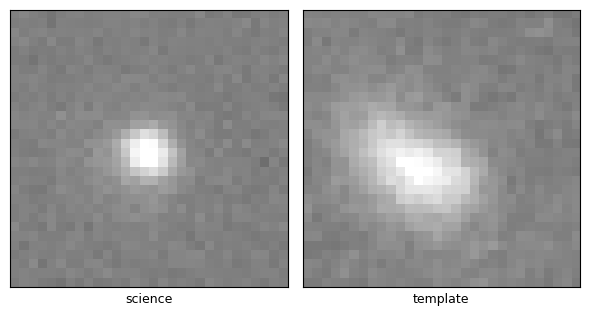

In [ ]:
def show(images, titles, difference_scale=None):
    """Display a row of images.

    Greyscale and auto-stretched by default. Pass `difference_scale` (an array of
    per-pixel noise, or a scalar) to show them instead as red/blue sigma maps on a
    shared +-8 scale.
    """
    fig, axes = plt.subplots(1, len(images), figsize=(3.0 * len(images), 3.2))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if difference_scale is None:
            limit = np.nanpercentile(np.abs(image), 99.5)
            ax.imshow(image, origin="lower", cmap="gray", vmin=-limit, vmax=limit)
        else:
            ax.imshow(image / difference_scale, origin="lower", cmap="RdBu_r",
                      vmin=-8, vmax=8)
        ax.set_xlabel(title, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    plt.show()


show([arrays["sci"], arrays["tmpl"]], ["science", "template"])

**Question.** The template shows a galaxy. The science image shows a point source.
Is the point source at the centre of the galaxy, or offset from it? Why might that
distinction matter for deciding what kind of event this is?

## 3. Why can't we just subtract?

The obvious thing is `science - template`. To see why that fails, we switch to a
different alert - one where the two images were taken in **very different seeing**.
Its science image has a PSF 15% wider than its template.

In [ ]:
def psf_fwhm(psf):
    """FWHM in pixels from the PSF's second moment, assuming a Gaussian core."""
    ny, nx = psf.shape          # alert PSF stamps are not always square
    y, x = np.mgrid[:ny, :nx]
    y, x = y - ny // 2, x - nx // 2
    second_moment = np.sum(psf * (x ** 2 + y ** 2)) / (2.0 * np.sum(psf))
    return 2.3548 * np.sqrt(second_moment)


science  PSF FWHM = 7.98 pixels
template PSF FWHM = 6.95 pixels
ratio = 1.15

naive subtraction peaks at 39 sigma
Rubin's difference peaks at 23 sigma


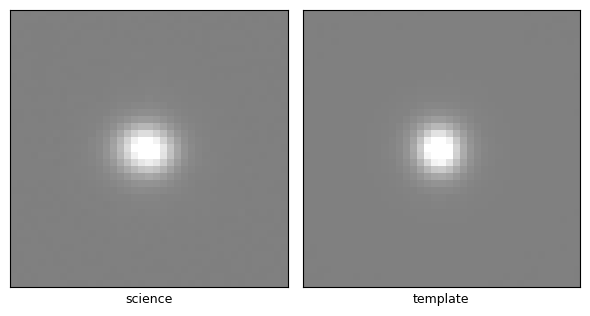

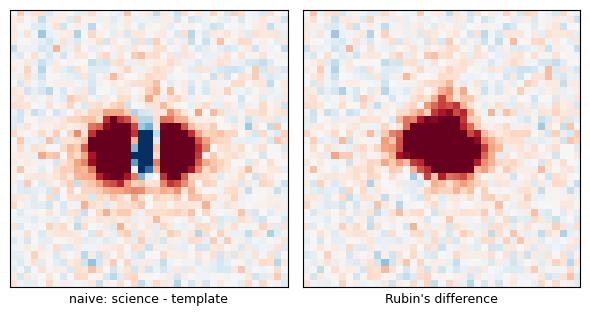

In [ ]:
# A different alert, chosen because its two images have badly mismatched seeing.
bad_arrays, bad_meta = load_alert("alert_real/seeing_mismatch.json.gz")

print(f"science  PSF FWHM = {psf_fwhm(bad_arrays['psf_sci']):.2f} pixels")
print(f"template PSF FWHM = {psf_fwhm(bad_arrays['psf_tmpl']):.2f} pixels")
print(f"ratio = {psf_fwhm(bad_arrays['psf_sci']) / psf_fwhm(bad_arrays['psf_tmpl']):.2f}")

naive = bad_arrays["sci"] - bad_arrays["tmpl"]
noise = np.sqrt(bad_arrays["sci_var"] + bad_arrays["tmpl_var"])
rubin = bad_arrays["rubin_diff"] / np.sqrt(np.clip(bad_arrays["diff_var"], 1e-30, None))

print(f"\nnaive subtraction peaks at {np.nanmax(np.abs(naive / noise)):.0f} sigma")
print(f"Rubin's difference peaks at {np.nanmax(np.abs(rubin)):.0f} sigma")

show([bad_arrays["sci"], bad_arrays["tmpl"]], ["science", "template"])
show([naive / noise, rubin], ["naive: science - template", "Rubin's difference"],
     difference_scale=1.0)

Look at the naive difference. A **single static source** has turned into two bright
lobes flanking a dark core. Nothing varied here - the structure is entirely an artifact
of subtracting two images whose PSFs have different widths. Rubin's difference, which
matched the PSFs first, leaves a single clean residual.

This is the whole problem of difference imaging. Every **static** star in the field
does this, leaving a positive-and-negative residual called a **dipole**, and on a bright
star the artifact is far larger than a real faint transient.

So before subtracting, one image must be **convolved** to match the other's PSF. The two
algorithms in the next sections are two ways of doing that.

**Exercise.** Go back and try the same naive subtraction on `alert_real/tns_2025ahkl.json.gz`,
whose PSF ratio is 0.94. How much does it differ from Rubin's there?

## 4. ZOGY: subtract in Fourier space

Zackay, Ofek & Gal-Yam (2016) (https://ui.adsabs.harvard.edu/abs/2016ApJ...830...27Z/abstract) showed there is an optimal difference image $D$,
given both PSFs. In Fourier space:

$$\widehat{D} = \frac{F_r \widehat{P_r} \widehat{N} - F_n \widehat{P_n} \widehat{R}}
{\sqrt{\sigma_n^2 F_r^2 |\widehat{P_r}|^2 + \sigma_r^2 F_n^2 |\widehat{P_n}|^2}}$$

where $N$ is the new (science) image, $R$ the reference (template), $P$ the PSFs,
$\sigma$ the noise levels and $F$ the photometric scales.

The denominator normalises $D$ so that **background noise has unit variance** - every
pixel of $D$ is already "how many sigma is this". Matched-filtering $D$ with its own
PSF gives $S_{\rm corr}$, the detection significance.

The implementation is below. It is about seventy lines of numpy: build the two
optical transfer functions, form $\widehat{D}$, matched-filter it, and propagate the
variance planes through the same filter so $S_{\rm corr}$ comes out in sigma.


In [ ]:
SEARCH_RADIUS = 5
NOISE_EXCLUSION = 15
EDGE_BAND = 5


def psf_to_otf(psf, shape):
    """FFT of a centred PSF stamp, cropped to fit, with its origin at pixel 0."""
    ny, nx = psf.shape
    my, mx = min(ny, shape[0]), min(nx, shape[1])
    my, mx = my - 1 + my % 2, mx - 1 + mx % 2
    if (my, mx) != (ny, nx):
        y0, x0 = (ny - my) // 2, (nx - mx) // 2
        psf = psf[y0:y0 + my, x0:x0 + mx]
        psf = psf / psf.sum()
    padded = np.zeros(shape)
    padded[:my, :mx] = psf
    return np.fft.fft2(np.roll(padded, (-(my // 2), -(mx // 2)), axis=(0, 1)))


def source_variance(variance_map, k_hat):
    """Propagate a variance plane through the matched filter k.

    Use the pipeline's variance plane rather than clip(image, 0) + sigma**2: that
    reconstruction is only valid for pixels in electrons, and Rubin's cutouts are
    calibrated to nJy, where flux and variance do not share units.
    """
    kernel = np.real(np.fft.ifft2(k_hat))
    return np.real(np.fft.ifft2(np.fft.fft2(variance_map) * np.fft.fft2(kernel ** 2)))


def zogy_difference(science, template, psf_sci, psf_tmpl, var_sci, var_tmpl,
                    sigma_sci, sigma_tmpl, flux_sci=1.0, flux_tmpl=1.0):
    """ZOGY difference of two registered, background-subtracted cutouts."""
    shape = science.shape
    n_hat, r_hat = np.fft.fft2(science), np.fft.fft2(template)
    pn_hat, pr_hat = psf_to_otf(psf_sci, shape), psf_to_otf(psf_tmpl, shape)
    f_n, f_r = flux_sci, flux_tmpl
    denom = np.sqrt(sigma_sci ** 2 * f_r ** 2 * np.abs(pr_hat) ** 2
                    + sigma_tmpl ** 2 * f_n ** 2 * np.abs(pn_hat) ** 2)
    d_hat = (f_r * pr_hat * n_hat - f_n * pn_hat * r_hat) / denom
    f_d = f_n * f_r / np.sqrt(sigma_sci ** 2 * f_r ** 2 + sigma_tmpl ** 2 * f_n ** 2)
    pd_hat = f_r * f_n * pr_hat * pn_hat / (f_d * denom)
    score = np.real(np.fft.ifft2(f_d * d_hat * np.conj(pd_hat)))
    # The science image is matched-filtered by conj(P_n), the template by conj(P_r).
    kn_hat = f_r ** 2 * f_n * np.abs(pr_hat) ** 2 * np.conj(pn_hat) / denom ** 2
    kr_hat = f_r * f_n ** 2 * np.abs(pn_hat) ** 2 * np.conj(pr_hat) / denom ** 2
    variance = source_variance(var_sci, kn_hat) + source_variance(var_tmpl, kr_hat)
    f_s = np.mean(f_r ** 2 * f_n * np.abs(pr_hat) ** 2 * np.abs(pn_hat) ** 2
                  / denom ** 2)
    return {"D": np.real(np.fft.ifft2(d_hat)),
            "P_D": np.fft.fftshift(np.real(np.fft.ifft2(pd_hat))),
            "S": score, "S_corr": score / np.sqrt(variance), "F_D": f_d, "F_S": f_s}


def peak_near_centre(score, radius=SEARCH_RADIUS):
    """Pixel of largest |score| within `radius` of the cutout centre."""
    centre = score.shape[0] // 2
    window = score[centre - radius:centre + radius + 1,
                   centre - radius:centre + radius + 1]
    dy, dx = np.unravel_index(np.argmax(np.abs(window)), window.shape)
    return centre - radius + dy, centre - radius + dx


def measure(arrays, meta):
    """Run ZOGY on one bundle and measure the source nearest the cutout centre."""
    result = zogy_difference(arrays["sci"], arrays["tmpl"],
                             arrays["psf_sci"], arrays["psf_tmpl"],
                             arrays["sci_var"], arrays["tmpl_var"],
                             meta["sigma_sci"], meta["sigma_tmpl"],
                             flux_sci=meta["f_sci"], flux_tmpl=meta["f_tmpl"])
    score = result["S_corr"]
    peak_y, peak_x = peak_near_centre(score)
    snr = score[peak_y, peak_x]
    flux = result["S"][peak_y, peak_x] / result["F_S"]
    # S_corr must have unit scatter away from sources; a departure flags bad inputs.
    size = score.shape[0]
    yy, xx = np.mgrid[:size, :size]
    quiet = np.zeros_like(score, dtype=bool)
    # Alert cutouts are only ~30 px, so the source-free annulus has to scale.
    edge = min(EDGE_BAND, max(1, size // 10))
    quiet[edge:-edge, edge:-edge] = True
    quiet &= np.hypot(yy - size // 2, xx - size // 2) > min(NOISE_EXCLUSION, size // 4)
    return {"result": result, "arrays": arrays, "meta": meta,
            "peak": (peak_y, peak_x), "snr": snr, "flux": flux,
            "flux_err": abs(flux / snr) if snr else np.inf,
            "noise_std": score[quiet].std()}


def compare_to_rubin(row):
    """Agreement with Rubin's own difference image and its DIA flux."""
    arrays, meta, result = row["arrays"], row["meta"], row["result"]
    noise = np.sqrt(np.clip(arrays["diff_var"], 1e-30, None))
    rubin_sigma = arrays["rubin_diff"] / noise
    ry, rx = peak_near_centre(rubin_sigma)
    return {"corr": np.corrcoef(arrays["rubin_diff"].ravel(),
                                result["D"].ravel())[0, 1],
            "rubin_snr": rubin_sigma[ry, rx],
            "offset_pix": float(np.hypot(ry - row["peak"][0], rx - row["peak"][1])),
            # ZOGY flux is in science-image units; divide by f_sci to reach nJy.
            "flux_ratio": row["flux"] / meta["f_sci"] / meta["dia_psf_flux_njy"],
            "alert_snr": meta["dia_snr"]}


ZOGY S_corr at the source : 95.2 sigma
Rubin's own snr           : 95.3 sigma
background scatter of D   : 2.57   (should be 1.0)


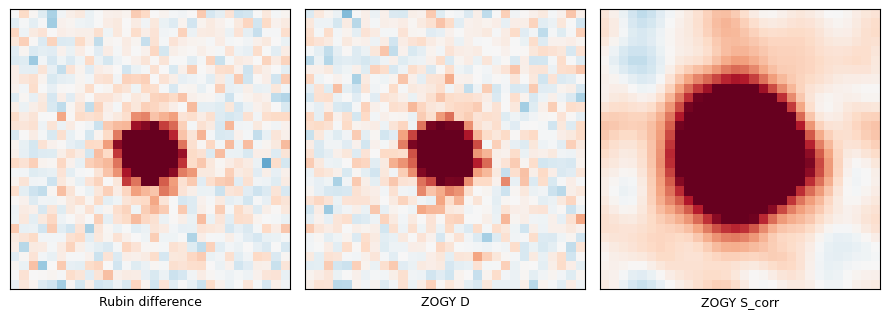

In [ ]:
zogy = measure(arrays, meta)

print(f"ZOGY S_corr at the source : {zogy['snr']:.1f} sigma")
print(f"Rubin's own snr           : {meta['dia_snr']:.1f} sigma")
print(f"background scatter of D   : {zogy['noise_std']:.2f}   (should be 1.0)")

show([arrays["rubin_diff"] / np.sqrt(arrays["diff_var"]),
      zogy["result"]["D"], zogy["result"]["S_corr"]],
     ["Rubin difference", "ZOGY D", "ZOGY S_corr"],
     difference_scale=1.0)

### Measuring the flux

Detection tells you *something changed*. Photometry tells you *by how much*.

$D$ is normalised so its background has unit variance, which means its pixels are in
units of sigma, not nJy. To recover a flux, matched-filter $D$ with its own PSF and
divide by a normalisation $F_S$ built from the two PSFs and the two noise levels:

$$F = \frac{S(\hat{x})}{F_S}, \qquad \sigma_F = \frac{|F|}{S_{\rm corr}(\hat{x})}$$

Two things are worth understanding here:

- **This is a matched filter, not an aperture.** Weighting each pixel by the PSF is the
  maximum-likelihood estimate of a point source's flux, so it recovers more
  signal-to-noise than summing pixels inside a circle. It is also why the uncertainty is
  just the flux divided by the detection significance - for an optimal filter the two
  carry the same information.
- **$F_S$ is where the units live.** Get it wrong and every flux scales by the same
  constant, which is invisible on a single object and obvious across a whole set. That is
  exactly why the check below runs over all nine alerts instead of one.

Rubin measures the same quantity a different way: it fits a PSF model to its own
difference image and reports `psfFlux`. Two independent methods on the same pixels should
agree, so any disagreement is telling you something.

In [ ]:
comparison = compare_to_rubin(zogy)
print(f"your ZOGY flux  : {zogy['flux']:>9.0f} +- {zogy['flux_err']:.0f} nJy")
print(f"Rubin psfFlux   : {meta['dia_psf_flux_njy']:>9.0f} +- {meta['dia_psf_flux_err_njy']:.0f} nJy")
print(f"ratio           : {comparison['flux_ratio']:.3f}")
print(f"correlation between your D and Rubin's difference : {comparison['corr']:.3f}")

your ZOGY flux  :     35948 +- 377 nJy
Rubin psfFlux   :     36449 +- 377 nJy
ratio           : 0.986
correlation between your D and Rubin's difference : 0.946


In [ ]:
print(f"{'target':>20} {'band':>5} {'your flux':>11} {'Rubin psfFlux':>14} "
      f"{'ratio':>7} {'your S_corr':>12} {'Rubin snr':>10}")
ratios = []
for path in bundles:
    one_arrays, one_meta = load_alert(path)
    one = measure(one_arrays, one_meta)
    ratio = one["flux"] / one_meta["dia_psf_flux_njy"]
    ratios.append(ratio)
    print(f"{one_meta['name'][:20]:>20} {one_meta['band']:>5} {one['flux']:>11.0f} "
          f"{one_meta['dia_psf_flux_njy']:>14.0f} {ratio:>7.3f} "
          f"{one['snr']:>12.1f} {one_meta['dia_snr']:>10.1f}")

ratios = np.array(ratios)
close = np.abs(ratios - 1) < 0.07
print(f"\n{close.sum()} of {len(ratios)} agree with Rubin to within 7 percent")
print(f"median ratio {np.median(ratios):.3f}")


              target  band   your flux  Rubin psfFlux   ratio  your S_corr  Rubin snr
     seeing_mismatch     z      273065         217413   1.256        123.2      102.5
        tns_2025agpz     r      107983         107259   1.007        267.5      269.5
        tns_2025ahkl     i       35948          36449   0.986         95.2       95.3
            asteroid     i       15481          14582   1.062         47.1       46.8
     galaxy_residual     r        6954            524  13.267         30.3       27.5
       masked_pixels     z      -69392         -65173   1.065        -61.3       38.9
   template_residual     i      -27463         -26494   1.037        -87.6       87.2
     vanished_source     z     -872862        -898859   0.971      -1012.3     1121.7
       variable_star     i      -19682         -18977   1.037        -38.5       38.2

7 of 9 agree with Rubin to within 7 percent
median ratio 1.037


**Read the ratio column, not the fluxes.** Seven of the nine agree with Rubin to within
7 percent, across four bands and four orders of magnitude in brightness - from 524 nJy to
−899000 nJy. That is the check that your $F_S$ is right: a units error would show up as
every row being off by the same factor, and it is not.

Note that the sign carries through. `vanished_source`, `template_residual`,
`variable_star` and `masked_pixels` are all **negative**, and your photometry reproduces
Rubin's negative fluxes to a few percent. Difference imaging measures change, and change
has a sign.

Two rows disagree, and both are informative:

- **`seeing_mismatch` at 1.256.** This is the badly-matched-PSF alert from section 3.
  ZOGY handles the mismatch in the difference image, but with a PSF ratio of 1.15 the
  flux still comes out 26 percent high. Difference imaging being *possible* is not the
  same as it being *accurate*.
- **`galaxy_residual` at 13.3** - your 6954 nJy against Rubin's 524 nJy. This is the
  faintest source in the set sitting on an 86000 nJy galaxy, and the two methods are
  measuring different things: your matched filter takes the peak within a few pixels of
  centre, which on a bright host lands on residual galaxy structure, while Rubin fits a
  PSF to its own difference image. On a marginal detection over a bright background,
  "the flux" is not a well-defined number until you say how you measured it.

## 5. Alard-Lupton: subtract in real space

Rubin's pipeline takes a different route, published by Alard & Lupton (1998) (https://ui.adsabs.harvard.edu/abs/1998ApJ...503..325A/abstract). Instead of needing both PSFs in Fourier space,
it **fits** the convolution kernel $K$ that turns the template's PSF into the science
PSF:

$$P_{\rm science} = P_{\rm template} \otimes K, \qquad
D = N - R \otimes K$$

$K$ is expanded in a basis of Gaussians times polynomials, so finding it is a single
linear least-squares solve.

The real question is what to fit $K$ **to**. Rubin fits it to the **detected stars**
across the whole detector: real point sources are what constrain a convolution kernel.
We cannot do that inside a single 30 pixel cutout - there is rarely a star in it, and
the only signal is usually a smooth galaxy, which tells you almost nothing about a
kernel.

The alert packet hands us the next best thing: the **PSF models themselves**. A PSF
model is a noiseless point source, so fitting

$$P_{\rm template} \otimes K = P_{\rm science}$$

is well conditioned. It also needs no masking - there is no transient inside a PSF model
for the fit to absorb.

And it comes with a free consistency check. Both PSF models are normalised to sum to 1,
so if the fit has worked then `sum(K)` has to come out at 1 **by itself**. Since `ksum`
is the template-to-science flux ratio, a value far from 1 means the photometric scaling
is wrong.


basis functions    : 9
kernel sum (ksum)  : 0.993   (should be 1 if the fit worked)
PSF match residual : 0.22%


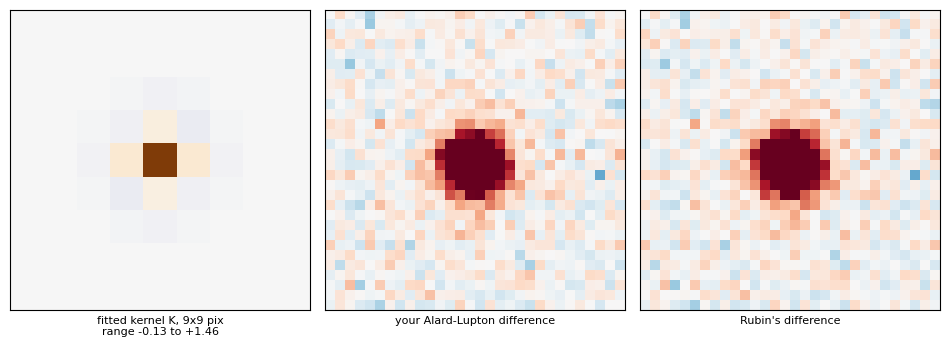

In [ ]:
def kernel_basis(half=4, sigmas=(0.7, 1.5), degrees=(2, 1)):
    """Alard-Lupton basis: Gaussians of different widths times polynomials in x, y."""
    y, x = np.mgrid[-half:half + 1, -half:half + 1].astype(float)
    basis = []
    for sigma, degree in zip(sigmas, degrees):
        envelope = np.exp(-(x ** 2 + y ** 2) / (2.0 * sigma ** 2))
        for i in range(degree + 1):
            for j in range(degree + 1 - i):
                basis.append(envelope * x ** i * y ** j)
    return np.array(basis)


def to_common_grid(psf, size=41):
    """Crop or zero-pad a PSF stamp onto a common odd grid, keeping it centred."""
    out = np.zeros((size, size))
    centre, out_centre = psf.shape[0] // 2, size // 2
    half = min(centre, out_centre)
    out[out_centre - half:out_centre + half + 1,
        out_centre - half:out_centre + half + 1] = \
        psf[centre - half:centre + half + 1, centre - half:centre + half + 1]
    return out / out.sum()


def kernel_from_psfs(psf_sci, psf_tmpl, size=41):
    """Fit K in the Alard-Lupton basis so that psf_tmpl (x) K matches psf_sci."""
    target = to_common_grid(psf_sci, size)
    source = to_common_grid(psf_tmpl, size)
    basis = kernel_basis()
    columns = np.array([fftconvolve(source, b, mode="same").ravel() for b in basis])
    coefficients, *_ = np.linalg.lstsq(columns.T, target.ravel(), rcond=None)
    kernel = np.tensordot(coefficients, basis, axes=(0, 0))
    model = np.tensordot(coefficients, columns, axes=(0, 0))
    residual = np.sqrt(np.mean((model - target.ravel()) ** 2)) / target.max()
    return kernel, residual


def alard_lupton(arrays):
    """Difference and its per-pixel noise, using K fitted to the two PSF models."""
    kernel, residual = kernel_from_psfs(arrays["psf_sci"], arrays["psf_tmpl"])
    difference = arrays["sci"] - fftconvolve(arrays["tmpl"], kernel, mode="same")
    variance = arrays["sci_var"] + fftconvolve(arrays["tmpl_var"], kernel ** 2,
                                               mode="same")
    return difference, np.sqrt(variance), kernel, residual


difference, al_noise, kernel, residual = alard_lupton(arrays)

print(f"basis functions    : {len(kernel_basis())}")
print(f"kernel sum (ksum)  : {kernel.sum():.3f}   (should be 1 if the fit worked)")
print(f"PSF match residual : {residual:.2%}")

# The kernel needs its own colour scale: on the +-8 sigma scale used for difference
# images it would be almost invisible.
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.5))
limit = np.abs(kernel).max()
axes[0].imshow(kernel, origin="lower", cmap="PuOr_r", vmin=-limit, vmax=limit)
axes[0].set_xlabel(f"fitted kernel K, {kernel.shape[0]}x{kernel.shape[1]} pix\n"
                   f"range {kernel.min():+.2f} to {kernel.max():+.2f}", fontsize=8)
for ax, image, title in zip(axes[1:],
                            [difference / al_noise,
                             arrays["rubin_diff"] / np.sqrt(arrays["diff_var"])],
                            ["your Alard-Lupton difference", "Rubin's difference"]):
    ax.imshow(image, origin="lower", cmap="RdBu_r", vmin=-8, vmax=8)
    ax.set_xlabel(title, fontsize=8)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()


**Look at the kernel.** It is dominated by a single positive core with weak negative
lobes around it, spanning about -0.13 to +1.46. Those negative lobes are doing something
specific: in this packet the template PSF is slightly *broader* than the science PSF
(6.95 against 6.55 pixels, measured in section 3), so $K$ has to **sharpen** the template
a little - and sharpening is exactly what negative lobes do.

**`ksum` is the check that matters.** Nothing in the fit forces it to 1, and it comes out
at 0.993 on its own. Across all 34 packets in this teaching set it stays between 0.892
and 1.013. That is the evidence the photometric scaling is right.

Fitting this same basis to the **image** instead - masking the candidate and using
whatever static flux is left - is far less stable on cutouts this small, because a smooth
galaxy barely constrains a kernel at all. On these packets it returns `ksum` anywhere
from 0.34 to 2.

**What this is and is not.** Rubin fits its kernel to **detected stars** on the full
detector, not to PSF models. That is more robust, because real stars also expose where
the PSF model itself is wrong, and a fit to the model cannot see its own error. Working
from the models is the practical substitute when all you have is one small cutout, and it
is closer in spirit to ZOGY, which also builds everything from the PSFs.

**Exercise.** Re-run the cell above on `alert_bogus/variable_star.json.gz` and on
`alert_real/seeing_mismatch.json.gz` - the two packets here with a bright static source. Does
`ksum` stay near 1, and does your difference still agree with Rubin's?

In [ ]:
def al_photometry(arrays, background_radius=10):
    """PSF-weighted flux on an Alard-Lupton difference, measured at the cutout centre.

    The difference carries the science PSF, so that is the weighting function. Pixels
    are weighted by psf/variance, which is the optimal-weight estimator, and a residual
    background is removed using the pixels outside `background_radius`.
    """
    difference, noise, kernel, _ = alard_lupton(arrays)
    variance = noise ** 2
    size = difference.shape[0]
    centre = size // 2
    yy, xx = np.mgrid[:size, :size]
    outskirts = np.hypot(yy - centre, xx - centre) > background_radius
    difference = difference - np.median(difference[outskirts])

    psf = arrays["psf_sci"]
    psf_centre = psf.shape[0] // 2
    half = min(psf_centre, centre - 1)
    stamp = psf[psf_centre - half:psf_centre + half + 1,
                psf_centre - half:psf_centre + half + 1]
    stamp = stamp / stamp.sum()
    cut = (slice(centre - half, centre + half + 1),) * 2
    weight = stamp / variance[cut]
    flux = float(np.sum(difference[cut] * weight) / np.sum(stamp * weight))
    error = float(1.0 / np.sqrt(np.sum(stamp ** 2 / variance[cut])))
    return flux, error, kernel.sum()


print(f"{'target':>20} {'ZOGY':>10} {'A-L':>10} {'Rubin':>10} "
      f"{'A-L/Rubin':>10} {'ZOGY/Rubin':>11} {'ksum':>6}")
al_ratios, zogy_ratios = [], []
for path in bundles:
    one_arrays, one_meta = load_alert(path)
    zogy_flux = measure(one_arrays, one_meta)["flux"]
    al_flux, al_error, ksum = al_photometry(one_arrays)
    rubin_flux = one_meta["dia_psf_flux_njy"]
    al_ratios.append(al_flux / rubin_flux)
    zogy_ratios.append(zogy_flux / rubin_flux)
    print(f"{one_meta['name'][:20]:>20} {zogy_flux:>10.0f} {al_flux:>10.0f} {rubin_flux:>10.0f} "
          f"{al_flux / rubin_flux:>10.3f} {zogy_flux / rubin_flux:>11.3f} {ksum:>6.3f}")

al_ratios, zogy_ratios = np.array(al_ratios), np.array(zogy_ratios)
for label, r in (("Alard-Lupton", al_ratios), ("ZOGY", zogy_ratios)):
    print(f"\n{label:13s} median {np.median(r):.3f}, "
          f"{(np.abs(r - 1) < 0.07).sum()} of {len(r)} within 7 percent")


              target       ZOGY        A-L      Rubin  A-L/Rubin  ZOGY/Rubin   ksum
     seeing_mismatch     273065     262113     217413      1.206       1.256  0.984
        tns_2025agpz     107983     107132     107259      0.999       1.007  0.992
        tns_2025ahkl      35948      32183      36449      0.883       0.986  0.993
            asteroid      15481      13757      14582      0.943       1.062  1.009
     galaxy_residual       6954       1972        524      3.763      13.267  1.000
       masked_pixels     -69392     -61954     -65173      0.951       1.065  0.978
   template_residual     -27463     -27044     -26494      1.021       1.037  0.978
     vanished_source    -872862    -860480    -898859      0.957       0.971  0.985
       variable_star     -19682     -19231     -18977      1.013       1.037  0.979

Alard-Lupton  median 0.999, 6 of 9 within 7 percent

ZOGY          median 1.037, 7 of 9 within 7 percent


**Two methods, the same pixels, different answers.** Alard-Lupton's median ratio is
0.999 against Rubin, slightly better centred than ZOGY's 1.037, but with marginally more
scatter - 6 of 9 within 7 percent against ZOGY's 7 of 9. Neither is simply "better", and
`ksum` stays between 0.978 and 1.009 throughout, so the kernel is not the problem.

The interesting row is `galaxy_residual`, where Alard-Lupton gives 1972 nJy and ZOGY
gives 6954 against Rubin's 524. Both are wrong, but ZOGY is wrong by 13x and A-L by
3.8x, and the reason is **not** the subtraction - it is *where each method measures*:

- `al_photometry` evaluates the flux at the **cutout centre**, the position Rubin
  reported.
- `measure` takes the **peak of $S_{\rm corr}$ within 5 pixels** of the centre.

On a faint source over a bright galaxy, that peak search wanders onto residual host
structure and reports it as flux. On the eight well-behaved rows the two agree closely,
because there the peak really is the source. This is a general lesson about photometry
code: a free centroid helps when the source dominates and hurts when it does not.

Notice also that Alard-Lupton runs slightly **low** on the two cleanest point sources -
`tns_2025ahkl` at 0.883 and `asteroid` at 0.943 - while ZOGY has those at 0.986 and
1.062. Our A-L here uses a single kernel fitted to the PSF models and subtracts a median
background from one small stamp; Rubin fits a spatially varying kernel across the whole
detector and models the background properly.

**Exercise.** Change `background_radius` in `al_photometry` from 10 to 8 and then to 13,
and watch `tns_2025ahkl`. How much of the 12 percent shortfall is the background
estimate? On a 30 pixel stamp, how much of the "background" annulus is actually host
galaxy?

### Decorrelation

Convolving the template by $K$ **correlates** its noise - neighbouring pixels are no
longer independent. Rubin applies a filter afterwards to whiten it again:

$$\widehat{\phi}(k) = \sqrt{\frac{\sigma_s^2 + \sigma_t^2 k_{\rm sum}^2}
{\sigma_s^2 + \sigma_t^2 |\widehat{K}(k)|^2}}$$

This does not improve the signal-to-noise; it makes the per-pixel noise statistics
honest, so that thresholding at 5 sigma really means 5 sigma.

(https://dmtn-021.lsst.io/)

**Exercise.** How strong is this correction for Rubin data? Compute the fraction of
the difference variance that comes from the template, using `sigma_sci` and
`sigma_tmpl` from the packet. Given how deep Rubin's templates are, would you expect
decorrelation to matter much here?

## 6. Real or bogus?

Rubin will issue roughly 10 million alerts a night, and **most difference-image
detections are not real transients**. Telling them apart is the first skill of
time-domain astronomy.

Below are Rubin's own difference images for nine alerts. **Classify them yourself
before running the next cell.** Red is brighter than the template, blue is fainter.

What to look for:

- **smooth, round, single-signed**, about as wide as the PSF -> likely real
- **side-by-side positive and negative lobes** -> registration error (a dipole)
- **concentric rings** around a bright star -> PSF mismatch
- **elongated or extended** -> something that is not a point source
- **sharp-edged or jagged** -> a detector artifact, or pixels the pipeline masked

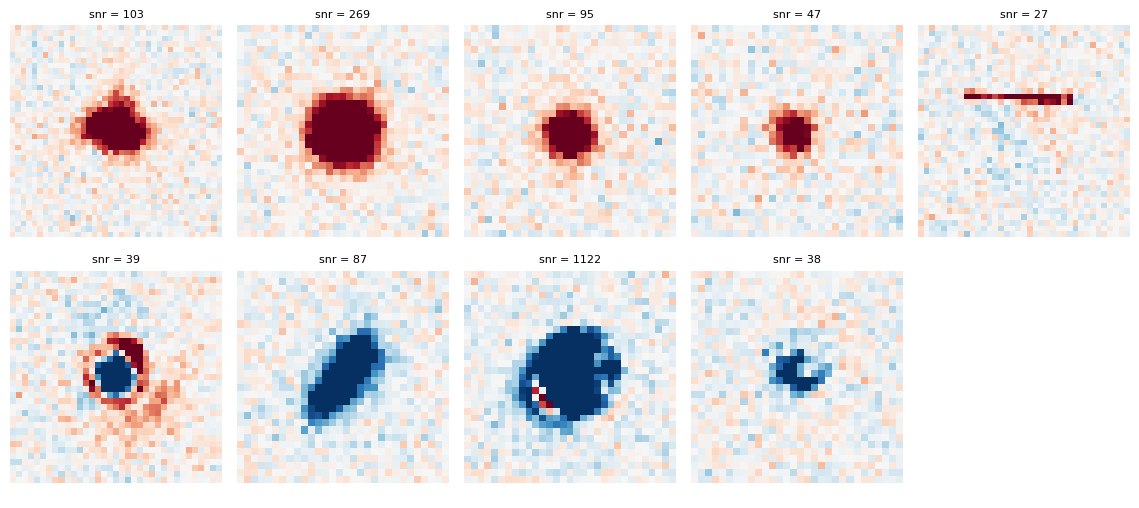

In [ ]:
def gallery(paths, labelled):
    """Rubin's difference image for each alert, on a shared +-8 sigma scale."""
    columns = 5
    rows = int(np.ceil(len(paths) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(2.3 * columns, 2.6 * rows))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, path in zip(axes.ravel(), paths):
        a, m = load_alert(path)
        snr = a["rubin_diff"] / np.sqrt(np.clip(a["diff_var"], 1e-30, None))
        ax.imshow(snr, origin="lower", cmap="RdBu_r", vmin=-8, vmax=8)
        name = m["name"].split("_17")[0].split("_31")[0]
        ax.set_title(f"{name}\nsnr = {m['dia_snr']:.0f}" if labelled
                     else f"snr = {m['dia_snr']:.0f}", fontsize=8)
        ax.axis("off")
    fig.tight_layout()
    return fig


gallery(bundles, labelled=False)
plt.show()

Now the labels. Three are real detections, six are not:

| label | what it is |
|---|---|
| `tns_2025agpz`, `tns_2025ahkl` | real transients, **confirmed in the Transient Name Server** |
| `seeing_mismatch` | a real detection whose two images have badly mismatched seeing - the section 3 example |
| `asteroid` | a **real** moving object - its template is blank because it moved |
| `variable_star` | a real star that faded by 12 percent, leaving a dipole |
| `template_residual` | an extended source in the template, absent from the science image |
| `vanished_source` | a bright source in the template of which **1 percent** survives in the science image |
| `galaxy_residual` | a subtraction residual on a bright galaxy, 0.6 percent of the host's flux |
| `masked_pixels` | a saturated star surrounded by pixels the pipeline flagged as unusable |

Note that `asteroid` and `variable_star` are **real detections of the wrong kind of
object**, which is a different problem from `masked_pixels` being an instrumental
artifact. A broker has to reject both, but for different reasons.

Three of these - `template_residual`, `vanished_source` and `galaxy_residual` - are
cases where **the template is brighter than the science image**, so the detection is
negative. That turns out to be the most common kind of junk in the stream, and only one
of the three has an explanation we are confident of. It is also not a handful of
oddities: scanning one night of the alert stream - 62794 alerts - **335 of them, 0.5
percent, have `psfFlux` within 10 percent of `-templateFlux`**, meaning a source present
in the template and essentially absent from the science image.

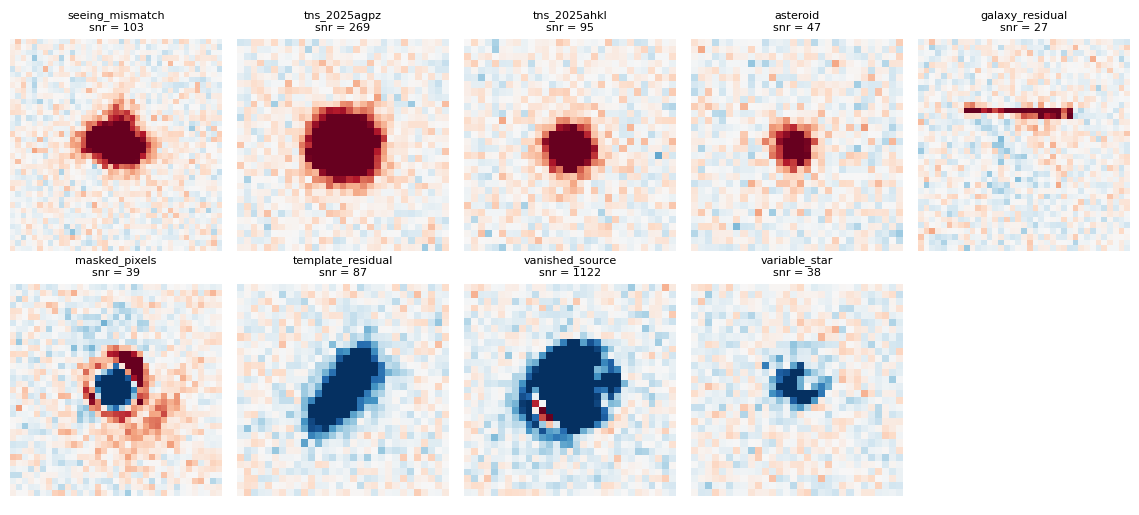

In [ ]:
gallery(bundles, labelled=True)
plt.show()

### Don't trust your eyes either - use the pipeline's numbers

Every alert carries Rubin's own quality measurements. Three are especially useful:

- **`extendedness`** - 0 for a point source, 1 for a fully extended one
- **`psf_chi`** - how well a PSF model fits. Rubin reports `psfChi2` and `psfNdata`
  rather than a reduced chi, so the download cell derives `sqrt(psfChi2 / psfNdata)`. About 1
  is a good fit; larger means it does not look like a point source. Note this is not on
  the same scale as the `chipsf` column some brokers publish
- **`pixelFlags_*`** - set when the footprint contains cosmic rays, streaks,
  saturation, bad columns or no data

These are computed by the pipeline on the full image, not reconstructed by us.

In [ ]:
def _num(value, places=2):
    """Format a diagnostic, or "-" when Rubin did not report one."""
    return "-" if value is None else f"{value:.{places}f}"


print(f"{'target':>22} {'snr':>6} {'flux':>9} {'extend':>7} {'psf_chi':>8} {'neg':>5}  flags")
for path in bundles:
    _, m = load_alert(path)
    name = m["name"].split("_17")[0].split("_31")[0]
    flags = ", ".join(m.get("flags_set") or []) or "-"
    print(f"{name[:22]:>22} {m['dia_snr']:>6.0f} {m['dia_psf_flux_njy']:>9.0f} "
          f"{_num(m['extendedness'], 3):>7} {_num(m['psf_chi']):>8} "
          f"{str(m['is_negative']):>5}  {flags}")

                target    snr      flux  extend  psf_chi   neg  flags
       seeing_mismatch    103    217413   0.312     1.28 False  -
          tns_2025agpz    269    107259   0.001     0.97 False  -
          tns_2025ahkl     95     36449   0.003     1.02 False  -
              asteroid     47     14582   0.181     1.05 False  -
       galaxy_residual     27       524       -     1.60 False  pixelFlags_cr, shape_flag
         masked_pixels     39    -65173       -     2.14 False  pixelFlags_bad, pixelFlags_cr, pixelFlags_saturated, pixelFlags_suspect, shape_flag
     template_residual     87    -26494   1.000     2.03  True  -
       vanished_source   1122   -898859   0.004     3.94  True  pixelFlags_cr
         variable_star     38    -18977   0.107     1.13  True  -


**What the numbers caught.** Each bogus case is caught by a different column, and one
is not caught at all:

- `template_residual` by **`extendedness` = 1.000** - it is not a point source
- `masked_pixels` by **five flags at once** - `pixelFlags_bad`, `pixelFlags_cr`,
  `pixelFlags_saturated`, `pixelFlags_suspect` and `shape_flag`. The pipeline is telling
  you outright that these pixels are unusable
- `vanished_source` by **`psf_chi` = 3.94** and by being negative at `snr` 1122
- `galaxy_residual` by **almost nothing**: `psf_chi` = 1.60 and only `pixelFlags_cr`,
  which fires on a fifth of all alerts. Its one real hint is `shape_flag`
- The confirmed transients sit at `extendedness` < 0.01 with `psf_chi` of 0.97 and
  1.02, about as close to a pure point source as this set gets

Notice that `extendedness` prints as `-` for exactly the two rows carrying
`shape_flag`. Rubin sets that flag when the shape fit fails, and then reports no
`extendedness` at all - a refusal to measure is itself a warning.

**But `asteroid` and `variable_star` pass every one of these cuts.** They are
point-like, fit a PSF well, and carry no flags - because they *are* real point
sources. No pixel-level diagnostic can reject them. Separating those out needs
different information.


**Exercise**: How would you identify asteroids in the alert stream? What extra info might you need?

### Scan through them yourself

Use the slider to step through every alert. For each one you get the science image,
the template, and Rubin's difference, plus the pipeline's own numbers.

Work through all of them and try to decide, before reading the label, whether you
would pass it to a human for follow-up. Pay attention to the **seeing ratio** printed
at the top: when it is far from 1 the two images have very different PSFs, and the
subtraction has more work to do.

In [ ]:
from ipywidgets import interact, IntSlider


def browse(index):
    """Science, template and Rubin difference for one alert, with its diagnostics."""
    arrays, meta = load_alert(bundles[index])
    ratio = psf_fwhm(arrays["psf_sci"]) / psf_fwhm(arrays["psf_tmpl"])
    noise = np.sqrt(np.clip(arrays["diff_var"], 1e-30, None))

    fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.6))
    for ax, image, title in zip(
            axes,
            [arrays["sci"], arrays["tmpl"], arrays["rubin_diff"] / noise],
            ["science", "template", "Rubin difference (sigma)"]):
        if title == "Rubin difference (sigma)":
            ax.imshow(image, origin="lower", cmap="RdBu_r", vmin=-8, vmax=8)
        else:
            limit = np.nanpercentile(np.abs(image), 99.5)
            ax.imshow(image, origin="lower", cmap="gray", vmin=-limit, vmax=limit)
        ax.set_xlabel(title, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

    name = meta["name"].split("_17")[0].split("_31")[0]
    fig.suptitle(
        f"[{index}] {name}    {meta['band']} = {meta['magpsf']:.2f}    "
        f"snr = {meta['dia_snr']:.0f}    flux = {meta['dia_psf_flux_njy']:+.0f} nJy\n"
        f"extendedness = {_num(meta['extendedness'], 3)}    psf_chi = {_num(meta['psf_chi'])}    "
        f"seeing ratio sci/tmpl = {ratio:.2f}    "
        f"flags: {', '.join(meta.get('flags_set') or ['none'])}",
        fontsize=9)
    fig.tight_layout()
    plt.show()


interact(browse, index=IntSlider(min=0, max=len(bundles) - 1, step=1, value=0,
                                 description="alert"))

interactive(children=(IntSlider(value=0, description='alert', max=8), Output()), _dom_classes=('widget-interac…

<function __main__.browse(index)>

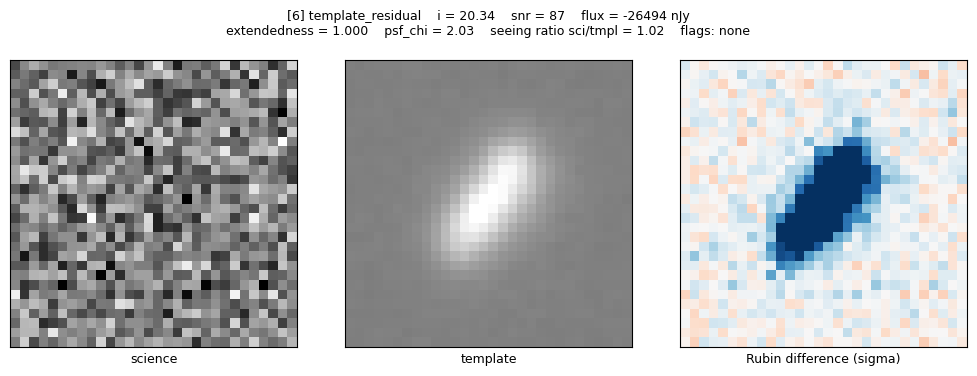

In [ ]:
browse(6)

If the slider does not appear (ipywidgets not installed, or the notebook opened in a
viewer that does not run widgets), just call the function directly:

```python
browse(0)    # then 1, 2, 3, ...
```

## 7. Was it a real discovery?

Several of these objects appear in the **Transient Name Server**, the public registry
where transient discoveries are reported. This one was reported as **AT 2025ahkl** at
discovery magnitude 19.6, and also picked up by GOTO, ATLAS and Pan-STARRS.

The prefix matters. `AT` means "astronomical transient" - reported, but not yet
classified. Once a spectrum classifies it, the Transient Name Server **renames it**: this
object is now **SN 2025ahkl**, a Type IIn supernova. The name itself tells you whether a
spectrum exists.

So when a broker's cross-match table returns `type = None` for `AT 2025ahkl`, that is a
statement about the table, not about the object. The classification exists; the snapshot
is keyed to the old designation. A missing `type` field means "not in this copy of the
catalogue", not "not classified".

**Exercise.** Before reading the next section, predict what a Type IIn light curve
should look like. Type IIn supernovae are powered by the shock running into dense
circumstellar material shed by the star before it exploded. Does that make them fade
faster or slower than a normal supernova?

## 8. Light curves: four objects, four physical classes

A light curve needs many epochs, but you do not need to measure them all yourself. The
approach here is the one a working astronomer would take:

- **measure a handful of epochs from the pixels**, to check that your photometry is
  right and to understand what the number means
- **take the rest from Rubin's catalogue**, which is in every alert packet as
  `prvDiaSources` and covers tens to hundreds of epochs

Each directory therefore has 6 or 7 packets for you to measure, and the object's full
catalogue photometry is already inside every one of them as `prvDiaSources`.

| directory | object | class | catalogue points |
|---|---|---|---|
| `lightcurve_2025ahkl` | SN 2025ahkl | **Type IIn** | 451 |
| `lightcurves/SN_IcBL_...` | 170230797176406143 | **Type Ic-BL** | 89 |
| `lightcurves/SN_Ia_...` | 170235219334922248 | **Type Ia** | 69 |
| `lightcurves/TDEcand_...` | 313871013537906708 | reported **candidate TDE** | 427 |

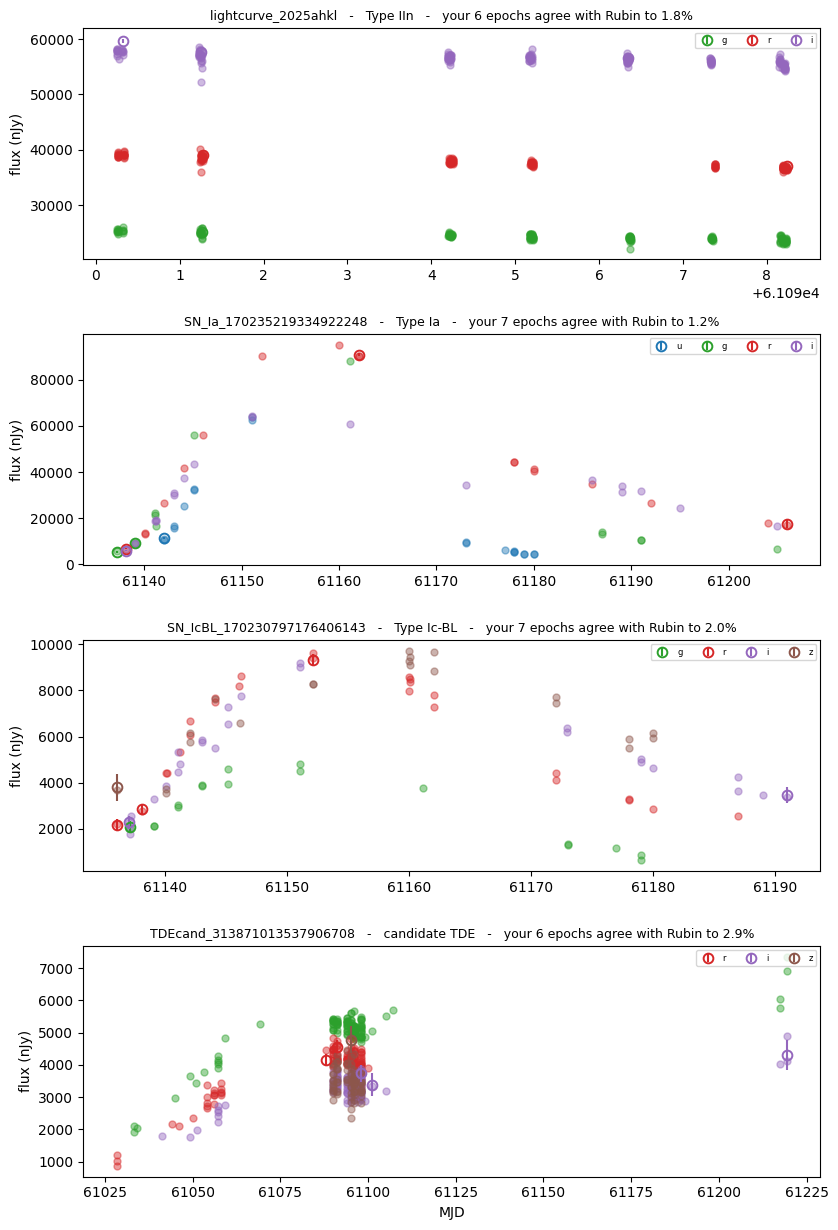

small dots = Rubin's catalogue photometry, open circles = your measurements from the pixels


In [ ]:
DIRECTORIES = ["lightcurve_2025ahkl"] + sorted(glob.glob("lightcurves/*"))
# Alert packets carry no classification, so the spectroscopic types are recorded here.
CLASSES = {"lightcurve_2025ahkl": "Type IIn",
           "lightcurves/SN_Ia_170235219334922248": "Type Ia",
           "lightcurves/SN_IcBL_170230797176406143": "Type Ic-BL",
           "lightcurves/TDEcand_313871013537906708": "candidate TDE"}
BAND_COLOUR = {"u": "tab:blue", "g": "tab:green", "r": "tab:red",
               "i": "tab:purple", "z": "tab:brown"}

fig, axes = plt.subplots(len(DIRECTORIES), 1, figsize=(8.5, 3.1 * len(DIRECTORIES)))
for ax, directory in zip(np.atleast_1d(axes), DIRECTORIES):
    # Rubin's catalogue photometry: the full light curve, small dots
    catalogue = catalogue_history(directory)
    for band, colour in BAND_COLOUR.items():
        points = [c for c in catalogue if c["band"] == band]
        if points:
            ax.plot([c["midpointMjdTai"] for c in points],
                    [c["psfFlux"] for c in points],
                    "o", color=colour, ms=5, alpha=0.45)

    # your own photometry on the cutouts: large open circles
    measured = []
    for path in sorted(glob.glob(f"{directory}/*.json.gz")):
        arrays, meta = load_alert(path)
        result = measure(arrays, meta)
        measured.append({"mjd": meta["jd"] - 2400000.5, "band": meta["band"],
                         "flux": result["flux"], "err": result["flux_err"],
                         "rubin": meta["dia_psf_flux_njy"]})
    label = CLASSES[directory]
    for band, colour in BAND_COLOUR.items():
        points = [m for m in measured if m["band"] == band]
        if points:
            ax.errorbar([m["mjd"] for m in points], [m["flux"] for m in points],
                        yerr=[m["err"] for m in points], fmt="o", color=colour,
                        ms=7, mfc="none", mew=1.4, label=band)

    ratio = np.array([m["flux"] / m["rubin"] for m in measured if m["rubin"]])
    ax.set_ylabel("flux (nJy)")
    ax.legend(fontsize=6, ncol=5, loc="upper right")
    ax.set_title(f"{os.path.basename(directory)}   -   {label}   -   "
                 f"your {len(measured)} epochs agree with Rubin to "
                 f"{abs(np.median(ratio) - 1) * 100:.1f}%", fontsize=9)
np.atleast_1d(axes)[-1].set_xlabel("MJD")
fig.tight_layout()
plt.show()

print("small dots = Rubin's catalogue photometry, "
      "open circles = your measurements from the pixels")

### Reading the four light curves

**Type Ia (`SN_Ia_...`)** is the most structured. Two features to find:

- `u` peaks at MJD 61151 near 63000 nJy, falls to 9000 by 61173 and 4000 by 61180,
  while `r` is still bright at 16900 nJy on 61206. Blue light fades first.
- In `i`, the flux falls to about 34000 nJy by 61173, then **rises again** to 36000 at
  61186 before resuming its decline. This **secondary maximum** in the red bands,
  roughly a month after peak, is a hallmark of Type Ia and comes from iron-group
  elements recombining in the ejecta. No other class here shows it.

**Type Ic-BL (`SN_IcBL_...`)** rises over about two weeks - 14 days in `g` and `i`, 16
in `r` - then fades. Notice the peak arrives later the redder you look: `g` and `i` peak
together at MJD 61151, `r` a day after, and `z` only at 61160. That is a photosphere
cooling as it expands.

**Type IIn (`lightcurve_2025ahkl`)** is nearly flat across the window we have: it fades
4 percent in `i` and 8 percent in `g` over the 8 days the catalogue covers. Type IIn are
powered by the shock running into dense circumstellar material the star shed before
exploding, which keeps them radiating far longer than a normal supernova. Be careful
with that inference here, though: 8 days is far too short a baseline to demonstrate a
slow decline, and plenty of supernovae are flat for 8 days near peak. All this light
curve establishes is that it is *consistent* with one.

**The TDE candidate** does not look like any of them. Over the 191 days it covers it
brightens, varies erratically, and is still rising to its maximum at the last epoch,
MJD 61219. It is also **nuclear** - offset from its host centre by 0.12 arcsec against a
1.3 arcsec PSF, i.e. unresolved, whereas SN 2025ahkl sits a resolved 0.67 arcsec from
its host. It has an ultraviolet counterpart in GALEX and a host photometric redshift.
Those last facts come from external catalogues, not from the alert packets.

**Exercise 1.** A tidal disruption event should decline smoothly, roughly as a power law
in time. An active galactic nucleus varies stochastically and can re-brighten. Which
does this light curve look like? What does the nuclear position *not* tell you?

**Exercise 2.** Rank the four by how long they stay within 1 magnitude of peak - and say
which one has too short a baseline for the question to be answerable. How would that
affect how often Rubin needs to observe a field to classify each type?

**Exercise 3.** Only one of these four was observed in `u`. Look at what `u` adds for the
Type Ia. What would you lose if you had only `riz`?

## 9. Going further

Things this notebook simplifies, which are real problems in the pipeline:

1. **Which image gets convolved.** Here the template PSF is broader than the science
   PSF (FWHM 6.95 vs 6.55 pixels), so our kernel has to sharpen the template slightly.
   Fitting to the PSF models keeps that stable, but sharpening amplifies noise and
   cannot recover detail the template never recorded. Rubin's pipeline chooses *which*
   image to convolve based on which PSF is wider; ours always convolves the template.
   Check the seeing ratios in section 6 and say which packets that choice would matter
   most for.

2. **One kernel per cutout.** Rubin fits a kernel that varies across the detector.
   Ours is constant across the stamp, which is why both methods degrade on bright
   stars where the residuals are strongest.

3. **Cutout size.** These are 30 to 39 pixels on a side. Alard-Lupton needs static sources to
   constrain the kernel, so it struggles when the template is blank; ZOGY needs no
   such fit but is sensitive to FFT edge effects. Which method would you trust on a
   hostless transient in an empty field?

4. **Saturation.** Several of the bright stars here are saturated, which breaks the
   linearity both algorithms assume.